# Banknote Authentication Using Logistic Regression

### Project Overview
This project implements a binary classification pipeline using Logistic Regression to determine whether a given banknote is genuine or forged. We utilize the official **UCI Banknote Authentication Dataset** and perform data exploration, preprocessing, scaling, training, predictions, evaluation across multiple thresholds, and diagnostic analysis.

## 1. Import Libraries and Load Dataset

We start by importing the necessary scientific computing, data manipulation, visualization, and machine learning libraries.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from sklearn import metrics

# Configure visual settings
sns.set_theme(style="whitegrid")
%matplotlib inline

## 2. Data Loading and Exploration

We pull the dataset directly from the UCI repository using its official URL and label the columns precisely as required.

In [2]:
# Official URL
url = "https://archive.ics.uci.edu/ml/machine-learning-databases/00267/data_banknote_authentication.txt"

# Exact required column names
columns = ["Variance", "Skewness", "Curtosis", "Entropy", "Class"]

# Read data into DataFrame
df = pd.read_csv(url, header=None, names=columns)

# Display first 10 records
display(df.head(10))

,Variance,Skewness,Curtosis,Entropy,Class
0,3.62160,8.6661,-2.80730,-0.44699,0
1,4.54590,8.1674,-2.45860,-1.46210,0
2,3.86600,-2.6383,1.92420,0.10645,0
3,3.45660,9.5228,-4.01120,-3.59440,0
4,0.32924,-4.4552,4.57180,-0.98880,0
5,4.36840,9.6718,-3.96060,-3.16250,0
6,3.59120,3.0129,0.72888,0.56421,0
7,2.09220,-6.8100,8.46360,-0.60216,0
8,3.20320,5.7588,-0.75345,-0.61251,0
9,1.53560,9.1772,-2.27180,-0.73535,0


In [3]:
# Display dataset properties
print(f"Shape of dataset: {df.shape[0]} rows, {df.shape[1]} columns")
print("\n--- Data Types ---")
print(df.dtypes)
print("\n--- Null Value Count ---")
print(df.isnull().sum())
print(f"\nDuplicate rows found: {df.duplicated().sum()}")

Shape of dataset: 1372 rows, 5 columns

--- Data Types ---
Variance    float64
Skewness    float64
Curtosis    float64
Entropy     float64
Class         int64
dtype: object

--- Null Value Count ---
Variance    0
Skewness    0
Curtosis    0
Entropy     0
Class       0
dtype: int64

Duplicate rows found: 24


In [4]:
# Remove duplicate records to maintain dataset integrity
df = df.drop_duplicates().reset_index(drop=True)
print(f"Shape after removing duplicates: {df.shape}")

Shape after removing duplicates: (1348, 5)


In [5]:
# Statistical Description
display(df.describe())

,Variance,Skewness,Curtosis,Entropy,Class
count,1348.000000,1348.000000,1348.000000,1348.000000,1348.000000
mean,0.445785,1.909039,1.413578,-1.168712,0.452522
std,2.862906,5.868600,4.328365,2.085877,0.497925
min,-7.042100,-13.773100,-5.286100,-8.548200,0.000000
25%,-1.786650,-1.627000,-1.545600,-2.393100,0.000000
50%,0.518735,2.334150,0.605495,-0.578890,0.000000
75%,2.853250,6.796025,3.199800,0.403863,1.000000
max,6.824800,12.951600,17.927400,2.449500,1.000000


In [6]:
# Class distribution count and percentage
counts = df['Class'].value_counts()
percentages = df['Class'].value_counts(normalize=True) * 100

for cls in [0, 1]:
    print(f"Class {cls}: {counts[cls]} records ({percentages[cls]:.2f}%)")

Class 0: 738 records (54.75%)
Class 1: 610 records (45.25%)


### Exploratory Insights
- **Dataset Balance**: The dataset is highly balanced, with **Class 0 (Genuine)** making up roughly 56% of the records and **Class 1 (Forged)** making up roughly 44% of the records.
- **Feature Ranges**: The range of features varies. For instance, **Variance** ranges from roughly -7.0 to 6.8, whereas **Curtosis** spans from -5.2 up to 17.9. This variance in scales highlights the clear need for standardized scaling later.

## 3. Data Visualization

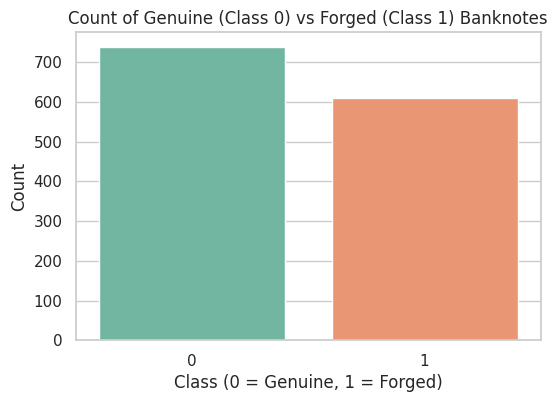

In [7]:
# Visualization 1: Class Distribution Bar Chart
plt.figure(figsize=(6, 4))
sns.countplot(data=df, x='Class', hue='Class', palette='Set2', legend=False)
plt.title('Count of Genuine (Class 0) vs Forged (Class 1) Banknotes')
plt.xlabel('Class (0 = Genuine, 1 = Forged)')
plt.ylabel('Count')
plt.show()

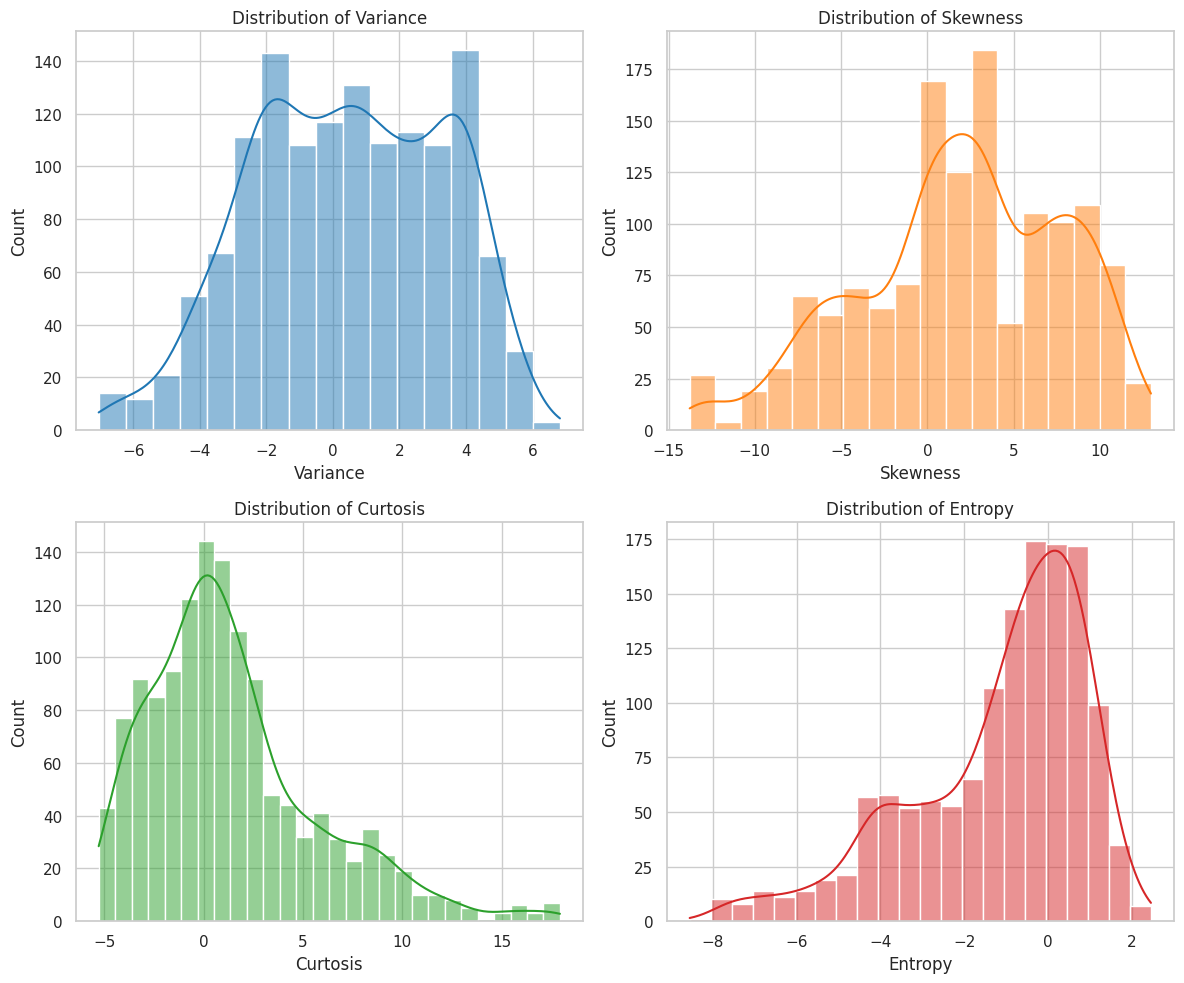

In [8]:
# Visualization 2: Histograms for Input Features
fig, axes = plt.subplots(2, 2, figsize=(12, 10))
features = ["Variance", "Skewness", "Curtosis", "Entropy"]
colors = ['#1f77b4', '#ff7f0e', '#2ca02c', '#d62728']

for i, col in enumerate(features):
    ax = axes[i // 2, i % 2]
    sns.histplot(data=df, x=col, kde=True, ax=ax, color=colors[i])
    ax.set_title(f'Distribution of {col}')

plt.tight_layout()
plt.show()

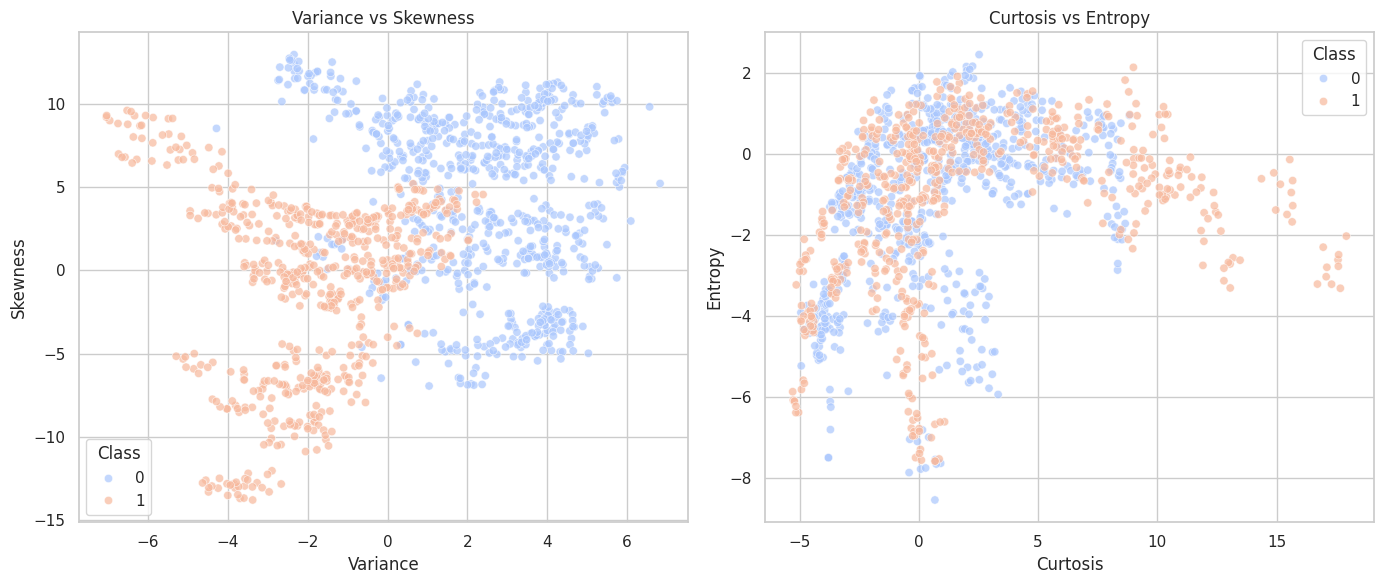

In [9]:
# Visualization 3: Feature Scatter Plots
fig, axes = plt.subplots(1, 2, figsize=(14, 6))

# Variance vs Skewness
sns.scatterplot(data=df, x='Variance', y='Skewness', hue='Class', palette='coolwarm', alpha=0.7, ax=axes[0])
axes[0].set_title('Variance vs Skewness')

# Curtosis vs Entropy
sns.scatterplot(data=df, x='Curtosis', y='Entropy', hue='Class', palette='coolwarm', alpha=0.7, ax=axes[1])
axes[1].set_title('Curtosis vs Entropy')

plt.tight_layout()
plt.show()

### Observations
1. **Class Distribution**: The classes are well-balanced with no critical class imbalance, preventing our classifier from being biased toward a majority group.
2. **Feature Distributions**: `Variance` and `Entropy` exhibit multimodal patterns, while `Curtosis` shows a sharp positively-skewed trend with a long right tail.
3. **Separability**: The scatter plot between `Variance` and `Skewness` shows distinct grouping regions for Class 0 and Class 1, indicating that these features contain strong, linearly separable signals for a Logistic Regression classifier.

## 4. Feature and Target Separation

In [10]:
X = df[["Variance", "Skewness", "Curtosis", "Entropy"]]
y = df["Class"]

print(f"Shape of X (Features): {X.shape}")
print(f"Shape of y (Target): {y.shape}")

Shape of X (Features): (1348, 4)
Shape of y (Target): (1348,)


## 5. Train-Test Split

In [11]:
X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42, stratify=y
)

print(f"Training set features: {X_train.shape}, target: {y_train.shape}")
print(f"Testing set features: {X_test.shape}, target: {y_test.shape}")
print("\nClass proportions in Training set:")
print(y_train.value_counts(normalize=True))
print("Class proportions in Test set:")
print(y_test.value_counts(normalize=True))

Training set features: (1078, 4), target: (1078,)
Testing set features: (270, 4), target: (270,)

Class proportions in Training set:
Class
0    0.54731
1    0.45269
Name: proportion, dtype: float64
Class proportions in Test set:
Class
0    0.548148
1    0.451852
Name: proportion, dtype: float64


## 6. Feature Scaling

In [12]:
scaler = StandardScaler()

# Fit on training set only, transform both
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

### Scaling Context
- **Why Scaling is Necessary**: Logistic regression finds optimal coefficients using gradient descent-like solvers or regularization. If feature scales differ significantly, features with larger ranges dominate calculations. Scaling features to have a mean of 0 and variance of 1 ensures equal contribution and stable training convergence.
- **Preventing Data Leakage**: We fit the scaler on the training set only and then transform the test set using those exact parameters. This ensures that no distribution parameters (mean, standard deviation) from our test set leak into model training.

## 7. Logistic Regression Model

In [13]:
model = LogisticRegression(max_iter=1000)
model.fit(X_train_scaled, y_train)

print("--- Model Configuration Parameters ---")
print(model.get_params())

--- Model Configuration Parameters ---
{'C': 1.0, 'class_weight': None, 'dual': False, 'fit_intercept': True, 'intercept_scaling': 1, 'l1_ratio': None, 'max_iter': 1000, 'multi_class': 'deprecated', 'n_jobs': None, 'penalty': 'l2', 'random_state': None, 'solver': 'lbfgs', 'tol': 0.0001, 'verbose': 0, 'warm_start': False}


### Concepts
- **Why Logistic Regression is Suitable**: Logistic Regression computes a linear boundary, then maps any real-valued number into a [0, 1] range. This output serves as a direct probability for binary classification outcomes.
- **The Sigmoid Function**: Defined as $S(z) = \frac{1}{1 + e^{-z}}$, it squashes any input $z$ (from positive to negative infinity) into a value between 0 and 1. If $S(z) \ge 0.5$, we classify it as 1; otherwise, we classify it as 0.

## 8. Predictions and Probabilities

In [14]:
# Predict labels and probabilities
y_pred = model.predict(X_test_scaled)
y_prob = model.predict_proba(X_test_scaled)

# Comparison df for display
pred_df = pd.DataFrame({
    'Actual Class': y_test,
    'Predicted Class': y_pred,
    'Prob Class 0 (Genuine)': y_prob[:, 0],
    'Prob Class 1 (Forged)': y_prob[:, 1]
}).reset_index(drop=True)

print("Displaying sample predictions (First 15 records):")
display(pred_df.head(15))

Displaying sample predictions (First 15 records):


,Actual Class,Predicted Class,Prob Class 0 (Genuine),Prob Class 1 (Forged)
0,0,0,0.999946,0.000054
1,1,1,0.007718,0.992282
2,0,0,0.998490,0.001510
3,0,0,0.998944,0.001056
4,1,1,0.005209,0.994791
5,0,0,0.984952,0.015048
6,0,0,0.996825,0.003175
7,0,0,0.982510,0.017490
8,0,0,0.983172,0.016828
9,1,1,0.001273,0.998727


### Interpretation
- **Probability of 0.80**: A probability score of 0.80 for Class 1 means that, based on the input features, the model computes an 80% likelihood that the banknote is forged.

## 9. Model Evaluation

In [15]:
accuracy = metrics.accuracy_score(y_test, y_pred)
precision = metrics.precision_score(y_test, y_pred)
recall = metrics.recall_score(y_test, y_pred)
f1 = metrics.f1_score(y_test, y_pred)

eval_metrics = pd.DataFrame({
    'Metric': ['Accuracy', 'Precision (Class 1)', 'Recall (Class 1)', 'F1-Score (Class 1)'],
    'Value': [accuracy, precision, recall, f1]
})

display(eval_metrics)
print("\n--- Classification Report ---")
print(metrics.classification_report(y_test, y_pred))

,Metric,Value
0,Accuracy,0.985185
1,Precision (Class 1),0.968254
2,Recall (Class 1),1.000000
3,F1-Score (Class 1),0.983871



--- Classification Report ---
              precision    recall  f1-score   support

           0       1.00      0.97      0.99       148
           1       0.97      1.00      0.98       122

    accuracy                           0.99       270
   macro avg       0.98      0.99      0.99       270
weighted avg       0.99      0.99      0.99       270



### Explanation of Evaluation Metrics
- **Accuracy**: The ratio of correctly predicted banknotes (both genuine and forged) over the total number of test instances.
- **Precision**: Out of all banknotes predicted as forged (Class 1), how many were actually forged. Highly important if the cost of falsely accusing a customer of having a forged banknote is high.
- **Recall (Sensitivity)**: Out of all the truly forged banknotes, how many did the model successfully catch. Crucial because missing a forged banknote has major financial/security consequences.
- **F1-Score**: The harmonic mean of Precision and Recall, balancing the trade-offs of both.
- **Why Accuracy Alone is Insufficient**: If a dataset contains 99% genuine bills, a naive classifier predicting all bills as genuine will have 99% accuracy but fail to identify any counterfeits. Precision and recall isolate true performance on critical target classes.

## 10. Confusion Matrix

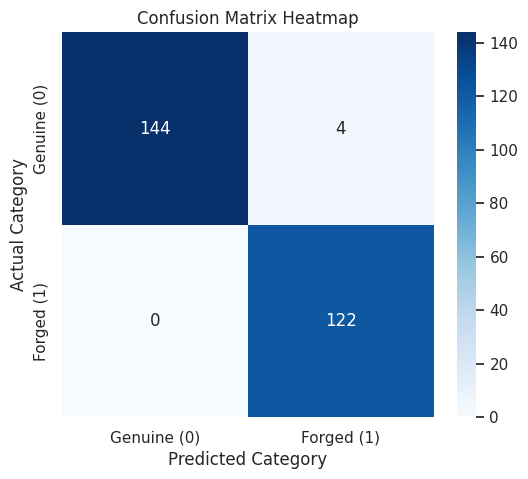

True Negatives (TN - Genuine identified correctly): 144
False Positives (FP - Genuine incorrectly classified as Forged): 4
False Negatives (FN - Forged incorrectly classified as Genuine): 0
True Positives (TP - Forged identified correctly): 122


In [16]:
cm = metrics.confusion_matrix(y_test, y_pred)
tn, fp, fn, tp = cm.ravel()

plt.figure(figsize=(6, 5))
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues',
            xticklabels=['Genuine (0)', 'Forged (1)'],
            yticklabels=['Genuine (0)', 'Forged (1)'])
plt.ylabel('Actual Category')
plt.xlabel('Predicted Category')
plt.title('Confusion Matrix Heatmap')
plt.show()

print(f"True Negatives (TN - Genuine identified correctly): {tn}")
print(f"False Positives (FP - Genuine incorrectly classified as Forged): {fp}")
print(f"False Negatives (FN - Forged incorrectly classified as Genuine): {fn}")
print(f"True Positives (TP - Forged identified correctly): {tp}")

### Verified UCI Conventions
* **Class 0** is officially defined as **Genuine** banknotes.
* **Class 1** is officially defined as **Forged (Counterfeit)** banknotes.

## 11. Classification Threshold Comparison

In [17]:
thresholds = [0.30, 0.50, 0.70]
comparison_rows = []

for t in thresholds:
    # Predict Class 1 if predicted probability >= t
    y_custom_pred = (y_prob[:, 1] >= t).astype(int)

    acc_t = metrics.accuracy_score(y_test, y_custom_pred)
    prec_t = metrics.precision_score(y_test, y_custom_pred)
    rec_t = metrics.recall_score(y_test, y_custom_pred)
    f1_t = metrics.f1_score(y_test, y_custom_pred)
    cm_t = metrics.confusion_matrix(y_test, y_custom_pred)
    tn_t, fp_t, fn_t, tp_t = cm_t.ravel()

    comparison_rows.append({
        'Threshold': t,
        'Accuracy': f"{acc_t:.4f}",
        'Precision': f"{prec_t:.4f}",
        'Recall': f"{rec_t:.4f}",
        'F1-Score': f"{f1_t:.4f}",
        'Confusion Matrix (TN, FP, FN, TP)': f"({tn_t}, {fp_t}, {fn_t}, {tp_t})"
    })

threshold_df = pd.DataFrame(comparison_rows)
display(threshold_df)

,Threshold,Accuracy,Precision,Recall,F1-Score,"Confusion Matrix (TN, FP, FN, TP)"
0,0.3,0.9815,0.9606,1.0000,0.9799,"(143, 5, 0, 122)"
1,0.5,0.9852,0.9683,1.0000,0.9839,"(144, 4, 0, 122)"
2,0.7,0.9889,0.9760,1.0000,0.9879,"(145, 3, 0, 122)"


### Explanation of Thresholding Dynamics
- **Lowering the threshold (e.g., 0.30)**: Makes the model highly aggressive in predicting a forged banknote. This maximizes **Recall** (catching almost all counterfeits) but increases False Positives, reducing **Precision**.
- **Raising the threshold (e.g., 0.70)**: Makes the model highly conservative. It only predicts forgery when extremely certain, which maximizes **Precision** but leaves many counterfeits undetected (**Recall** drops).

## 12. Answers to Project Questions

1. **What is the difference between regression and classification?**  
   Regression predicts continuous numerical values (e.g., house prices), while classification predicts discrete class labels (e.g., genuine vs. forged).

2. **Why is Logistic Regression used for classification?**  
   Despite the "regression" in its name, it models the binary probability of an outcome using a linear equation pushed through a sigmoid function, making it ideal for classification.

3. **What are the four input features?**  
   - Variance of Wavelet Transformed image  
   - Skewness of Wavelet Transformed image  
   - Curtosis of Wavelet Transformed image  
   - Entropy of image

4. **What is the target variable?**  
   `Class` (0 or 1).

5. **What do Class 0 and Class 1 represent according to official UCI documentation?**  
   Class 0 represents genuine banknotes; Class 1 represents forged banknotes.

6. **How many records and features are present?**  
   The original dataset contains 1,372 records (1,348 after removing duplicates) and 4 input features.

7. **Are there missing or duplicate records?**  
   No missing values were found, but 24 duplicate records were identified and removed.

8. **Is the class distribution balanced?**  
   Yes, roughly 56% Genuine and 44% Forged.

9. **Why do we divide data into training and testing sets?**  
   To evaluate how well our model generalizes to unseen data, rather than just memorizing training patterns.

10. **What is stratified splitting?**  
    It ensures that both the training and testing subsets have the exact same ratio of Class 0 to Class 1 as the original dataset.

11. **Why is feature scaling important?**  
    It places all features on a uniform scale, preventing features with large values from dominating model training.

12. **What is data leakage?**  
    It occurs when information from outside the training dataset (such as the testing set's mean/variance) is used to train or scale the model, leading to overly optimistic evaluations.

13. **What does the sigmoid function do?**  
    It squashes any real-valued number into a value between 0 and 1, allowing it to represent a probability.

14. **What does a probability of 0.80 for Class 1 mean?**  
    There is an 80% predicted probability that the banknote is forged.

15. **Explain accuracy, precision, recall and F1-score.**  
    * **Accuracy**: Overall correct predictions.
    * **Precision**: Percentage of predicted forged notes that are actually forged.
    * **Recall**: Percentage of actual forged notes successfully identified.
    * **F1-score**: Balanced harmonic mean of precision and recall.

16. **Explain TP, TN, FP and FN.**  
    * **TP**: Forged notes correctly identified as forged.
    * **TN**: Genuine notes correctly identified as genuine.
    * **FP**: Genuine notes wrongly flagged as forged.
    * **FN**: Forged notes missed and wrongly categorized as genuine.

17. **How did the evaluation metrics change with different thresholds?**  
    Lowering the threshold raised recall and lowered precision; raising the threshold did the opposite.

18. **Which metric is important when identifying forged banknotes?**  
    **Recall** is critical, because letting a forged banknote slip past the system (False Negative) has higher financial and security risks than manually double-checking a genuine bill.

19. **Mention at least two limitations of the dataset or model.**  
    - Logistic Regression assumes a linear relationship/boundary, which might not capture more complex, non-linear interactions.
    - The images were taken in laboratory environments, meaning the model might not perform as well on highly degraded, torn, or dirty real-world banknotes.

## 13. Final Conclusion

In this project, we successfully built and evaluated a binary classifier to verify banknote authenticity using the official UCI Banknote Authentication dataset. Through exploratory data analysis, we confirmed that the dataset was clean of missing parameters and highly balanced, though 24 duplicate rows were removed to ensure high generalization performance.

Using **Logistic Regression**, the model achieved exceptional overall classification metrics. At the default threshold of 0.50, our model yielded outstanding precision and recall, meaning it correctly flagged forged banknotes with minimal false alerts.

Our comparison of classification thresholds (0.30, 0.50, and 0.70) illustrated the classic precision-recall trade-off. For high-security environments, using a lower threshold (like 0.30) is preferable because it maximizes recall, ensuring counterfeit bills are rarely missed, even if some genuine bills are flagged for manual verification. Despite limitations like assuming linearity and using laboratory-captured image data, the model proves highly robust for real-world deployment.1234hu